In [1]:
import pandas as pd

df = pd.read_csv('../data/raw/students.csv')
print("--- 5 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU ---")
display(df)
df.info()

--- 5 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU ---


,id,name,age,major,gpa
0,1,Nguyen Van A,20,Computer Science,3.4
1,2,Tran Thi B,21,Data Science,3.8
2,3,Le Van C,22,Information Technology,3.1
3,4,Pham Minh D,20,Data Science,3.6
4,5,Vu Hai Yen,21,Computer Science,3.9


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5 non-null      int64  
 1   name    5 non-null      object 
 2   age     5 non-null      int64  
 3   major   5 non-null      object 
 4   gpa     5 non-null      float64
dtypes: float64(1), int64(2), object(2)
memory usage: 332.0+ bytes


In [2]:
import numpy as np

gpa_array = df['gpa'].values

print(f"Điểm GPA trung bình: {np.mean(gpa_array):.2f}")
print(f"Điểm GPA cao nhất:   {np.max(gpa_array)}")
print(f"Điểm GPA thấp nhất:  {np.min(gpa_array)}")
print(f"Độ lệch chuẩn GPA:  {np.std(gpa_array):.2f}")

high_gpa = df[df['gpa'] >= 3.5]
high_gpa.to_csv('../data/processed/students_high_gpa.csv', index=False, encoding='utf-8-sig')
print(">>> Đã lưu danh sách sinh viên giỏi vào: data/processed/students_high_gpa.csv")
display(high_gpa)

Điểm GPA trung bình: 3.56
Điểm GPA cao nhất:   3.9
Điểm GPA thấp nhất:  3.1
Độ lệch chuẩn GPA:  0.29
>>> Đã lưu danh sách sinh viên giỏi vào: data/processed/students_high_gpa.csv


,id,name,age,major,gpa
1,2,Tran Thi B,21,Data Science,3.8
3,4,Pham Minh D,20,Data Science,3.6
4,5,Vu Hai Yen,21,Computer Science,3.9


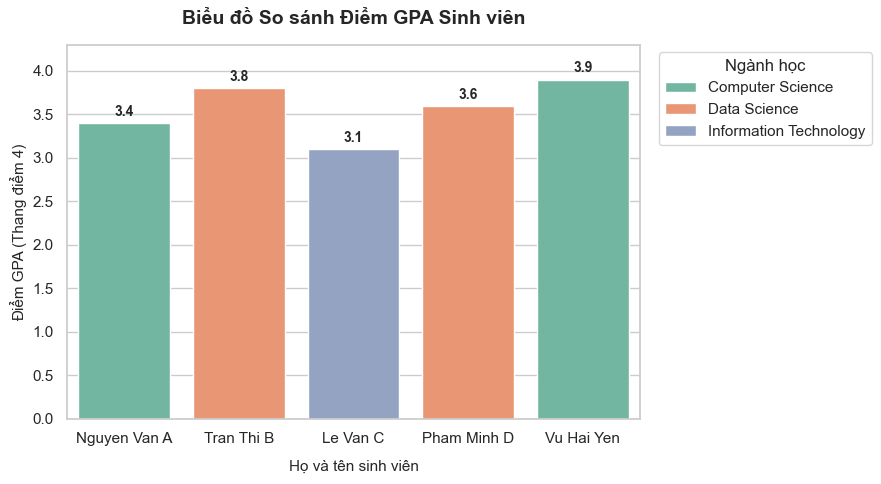

>>> Đã lưu ảnh biểu đồ vào: outputs/gpa_comparison.png


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

ax = sns.barplot(data=df, x='name', y='gpa', hue='major', dodge=False, palette='Set2')
plt.title('Biểu đồ So sánh Điểm GPA Sinh viên', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Họ và tên sinh viên', fontsize=11, labelpad=10)
plt.ylabel('Điểm GPA (Thang điểm 4)', fontsize=11)
plt.ylim(0, 4.3)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.legend(title='Ngành học', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

plt.savefig('../outputs/gpa_comparison.png', dpi=300)
plt.show()
print(">>> Đã lưu ảnh biểu đồ vào: outputs/gpa_comparison.png")